# Ballot-level anomalies — Bulgarian presidential election, round 2 / runoff (1 Nov 2026)

Same checks as `ballot_anomalies.ipynb` (round 1), applied to the **Йотова vs Гюров runoff**. The watch-list at the end also flags stations whose turnout surged between rounds and stations that were already flagged in round 1.

The previous notebooks looked for **invented numbers** (Benford) and **stuffed ballot boxes** (turnout fingerprints). This one
targets manipulation that happens **during the count or at the voters' list**, which changes neither digits nor turnout:

| # | Question | Method |
|---|---|---|
| 1 | Do **paper-ballot** stations give different results than **machine** stations? (Committees can tamper with paper during the count, not with machines.) | **Regression discontinuity** at the legal 300-voter threshold |
| 2 | Are there stations with suspiciously many **invalid ballots**, and does a high invalid rate favour anyone? | Beta-binomial outlier test vs. the municipality, plus a within-municipality regression |
| 3 | How do **voters added on election day** (“под чертата”) vote, and where are there unusually many? | Fixed-effects regression, plus outlier test |
| 4 | Do the **protocols add up**? | Arithmetic consistency checks |
| 5 | Which stations raise **several red flags at once**? | Combined watch-list (incl. flags from the earlier notebooks) |

A note on wording: every test here finds **statistical anomalies**. An anomaly is a reason to look at the scanned protocol or
observer reports, not proof of fraud.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from load_data import load_votes, load_sections, data_dir, ELECTIONS, ROUND1, ROUND2

votes = load_votes(election=ROUND2)
meta = load_sections(ROUND2)
NONE = "Не подкрепям никого"
cand_cols = [c for c in votes.columns if c != NONE]
ranked = list(votes[cand_cols].sum().sort_values(ascending=False).index)
TOP = ranked[:2]        # the two runoff candidates
OUTCOMES = TOP + [NONE]
short = lambda c: c.split(" ", 1)[1] if c[:2].isdigit() else c

# raw protocol rows (one main protocol per station: forms 24/26/28/30 = paper, 25/29 = machine)
proto = pd.read_csv(data_dir(ROUND2) / f"protocols_{ELECTIONS[ROUND2]}.txt", sep=";", header=None, dtype=str, names=range(1, 29))
proto = proto.set_index(2)
num = lambda s: pd.to_numeric(s, errors="coerce")
main = proto[proto[1].isin(["24", "25", "26", "28", "29", "30"])]

df = meta.join(votes)
df["form"] = main[1].astype(int)
df["registered"] = df["voters_list"] + df["voters_added"]
df["voted"] = df["voted_signatures"]
df["turnout"] = df["voted"] / df["registered"]
df["valid"] = votes.sum(axis=1)
df["invalid"] = num(main[13]).reindex(df.index).fillna(0).astype(int)   # paper only; machines cannot produce invalid votes
df["paper"] = df["machines"] == 0
for c in votes.columns:
    df[f"share|{c}"] = df[c] / df["valid"]
dom = df[~df["abroad"] & (df["mobile"] == 0) & (df["ship"] == 0) & (df["valid"] > 0)].copy()
print(f"{len(dom):,} domestic regular stations: {dom['paper'].sum():,} paper-only, {(~dom['paper']).sum():,} with machines")

11,841 domestic regular stations: 2,468 paper-only, 9,373 with machines


In [2]:
# ---- chart style ----
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#c3c2b7", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110,
    "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
def suptitle(fig, s): fig.suptitle(s, x=0.01, ha="left", fontsize=13, fontweight="bold")

# ---- small stats toolkit (numpy only) ----
def wls_cluster(y, X, w, groups):
    # Weighted least squares with cluster-robust (CR1) standard errors.
    y, X, w = np.asarray(y, float), np.asarray(X, float), np.asarray(w, float)
    sw = np.sqrt(w); Xw, yw = X * sw[:, None], y * sw
    XtX_inv = np.linalg.pinv(Xw.T @ Xw)
    beta = XtX_inv @ Xw.T @ yw
    u = yw - Xw @ beta
    g = pd.factorize(np.asarray(groups))[0]; G = g.max() + 1
    S = np.zeros((G, X.shape[1])); np.add.at(S, g, Xw * u[:, None])
    n, k = X.shape
    V = XtX_inv @ (S.T @ S) @ XtX_inv * (G / (G - 1)) * ((n - 1) / max(n - k, 1))
    return beta, np.sqrt(np.diag(V))

def demean(a, groups, w):
    # Subtract the weighted group mean = fixed effects for each group.
    a = pd.DataFrame(np.asarray(a, float)); g = pd.Series(np.asarray(groups)); w = pd.Series(np.asarray(w, float))
    m = a.mul(w, axis=0).groupby(g).transform("sum").div(w.groupby(g).transform("sum"), axis=0)
    return (a - m).to_numpy()

def betabinom_outliers(x, n, p_expected, q=0.01):
    # One-sided test for 'too many' events given an expected rate, allowing for over-dispersion (beta-binomial).
    # Returns (q-values, fitted intra-class correlation rho).
    # rho (extra between-station variation) is fitted by maximum likelihood.
    from scipy.optimize import minimize_scalar
    x, n, p = np.asarray(x, float), np.asarray(n, float), np.clip(np.asarray(p_expected, float), 1e-4, 0.999)
    xi, ni = x.astype(int), n.astype(int)
    nll = lambda r: -stats.betabinom.logpmf(xi, ni, p * (1 - r) / r, (1 - p) * (1 - r) / r).sum()
    rho = float(minimize_scalar(nll, bounds=(1e-5, 0.3), method="bounded").x)
    a, b = p * (1 - rho) / rho, (1 - p) * (1 - rho) / rho
    pv = np.where(x > 0, stats.betabinom.sf(x - 1, n.astype(int), a, b), 1.0)
    return stats.false_discovery_control(np.clip(pv, 0, 1)), rho

def loo_rate(events, trials, groups, fallback):
    # Rate in the rest of the municipality (leave-one-out), so a station isn't compared with itself.
    g = pd.Series(np.asarray(groups))
    e, t = pd.Series(np.asarray(events, float)), pd.Series(np.asarray(trials, float))
    r = (e.groupby(g).transform("sum") - e) / (t.groupby(g).transform("sum") - t)
    return r.where(np.isfinite(r), fallback).fillna(fallback).to_numpy()

## 1. Paper vs machine: a natural experiment at 300 voters
By law, stations with **300 or more** voters on the list vote by machine and smaller ones vote on paper. Our data follow the rule
exactly. Stations with 290 and 310 voters come from the same kinds of neighbourhoods; **only the voting method differs**.

So if paper counts were systematically manipulated in someone's favour, that candidate's share would **jump** at the 300 line.
This is a *regression discontinuity design* (RDD): fit a line on each side and measure the gap at 300.

In [3]:
lo_hi = dom.groupby(pd.cut(dom["voters_list"], [0, 200, 280, 300, 320, 400, 10**6], right=False), observed=True)["paper"].agg(["size", "mean"])
lo_hi.columns = ["stations", "share using paper"]
lo_hi.style.format({"share using paper": "{:.1%}"})

,stations,share using paper
voters_list,,
"[0, 200)",2007,96.7%
"[200, 280)",451,96.0%
"[280, 300)",101,92.1%
"[300, 320)",133,0.0%
"[320, 400)",541,0.0%
"[400, 1000000)",8608,0.0%


**Validity check: is there bunching at the threshold?** If officials split stations to keep them just under 300 (to avoid
machines), there would be too many stations at 280–299 and too few at 300–319. That would itself be a red flag, and it would
make the comparison unfair.

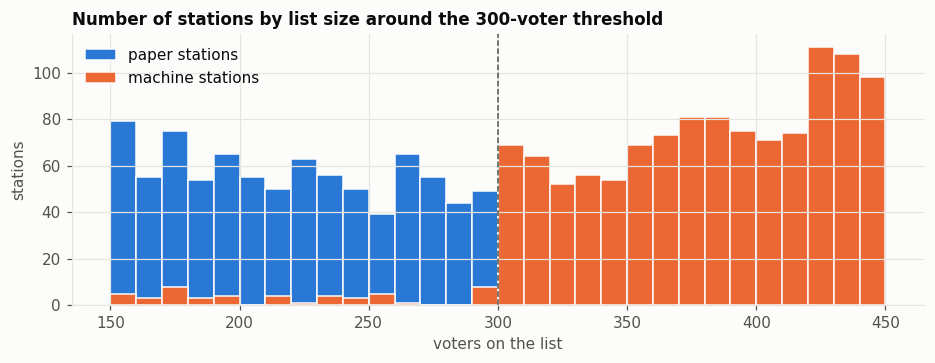

stations with 280–299 voters: 101;  300–319: 133  (binomial test for a difference: p = 0.04)


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
w = dom[(dom["voters_list"] >= 150) & (dom["voters_list"] < 450)]
bins = np.arange(150, 451, 10)
ax.hist(w.loc[w["paper"], "voters_list"], bins=bins, color=BLUE, edgecolor=SURFACE, label="paper stations")
ax.hist(w.loc[~w["paper"], "voters_list"], bins=bins, color=ORANGE, edgecolor=SURFACE, label="machine stations")
ax.axvline(300, color=INK2, lw=1, ls="--")
ax.set_xlabel("voters on the list"); ax.set_ylabel("stations"); ax.legend()
ax.set_title("Number of stations by list size around the 300-voter threshold")
plt.show()
below, above = ((w["voters_list"] >= 280) & (w["voters_list"] < 300)).sum(), ((w["voters_list"] >= 300) & (w["voters_list"] < 320)).sum()
print(f"stations with 280–299 voters: {below};  300–319: {above}  "
      f"(binomial test for a difference: p = {stats.binomtest(below, below + above).pvalue:.2f})")

In [5]:
def rd_estimate(data, y_col, bw, fe=False):
    s = data[(data["voters_list"] >= 300 - bw) & (data["voters_list"] < 300 + bw)]
    x = (s["voters_list"] - 300).to_numpy(float); M = (x >= 0).astype(float)
    y = s[y_col].to_numpy(float); wts = s["valid"].to_numpy(float)
    if fe:   # compare stations within the same municipality
        X = demean(np.column_stack([M, x, M * x]), s["municipality"], wts)
        y = demean(y, s["municipality"], wts)[:, 0]
        b, se = wls_cluster(y, X, wts, s["municipality"]); return b[0], se[0], len(s)
    X = np.column_stack([np.ones(len(s)), M, x, M * x])
    b, se = wls_cluster(y, X, wts, s["municipality"]); return b[1], se[1], len(s)

dom["invalid share"] = dom["invalid"] / (dom["invalid"] + dom["valid"])
rd_outcomes = {short(c): f"share|{c}" for c in OUTCOMES} | {"turnout": "turnout", "invalid ballots (positive control)": "invalid share"}
rows = {}
for name, col in rd_outcomes.items():
    for bw in [50, 100]:
        for fe in [False, True]:
            b, se, n = rd_estimate(dom, col, bw, fe)
            rows.setdefault(name, {})[f"±{bw} voters{' + municipality FE' if fe else ''}"] = f"{b*100:+.1f} ± {1.96*se*100:.1f}"
rd_tab = pd.DataFrame(rows).T
print("Jump at 300 voters (machine minus paper), percentage points, ± 95% CI")
rd_tab

Jump at 300 voters (machine minus paper), percentage points, ± 95% CI


,±50 voters,±50 voters + municipality FE,±100 voters,±100 voters + municipality FE
Илияна Йотова,+0.5 ± 5.0,+1.6 ± 4.1,+1.1 ± 4.4,+1.4 ± 2.9
Андрей Гюров,-0.7 ± 4.8,-2.2 ± 4.0,-1.1 ± 4.3,-1.7 ± 2.7
Не подкрепям никого,+0.2 ± 0.7,+0.5 ± 0.8,+0.0 ± 0.5,+0.3 ± 0.6
turnout,-3.0 ± 8.6,+0.3 ± 8.0,-6.1 ± 6.5,-6.6 ± 5.7
invalid ballots (positive control),-1.4 ± 0.5,-1.4 ± 0.7,-1.3 ± 0.3,-1.3 ± 0.4


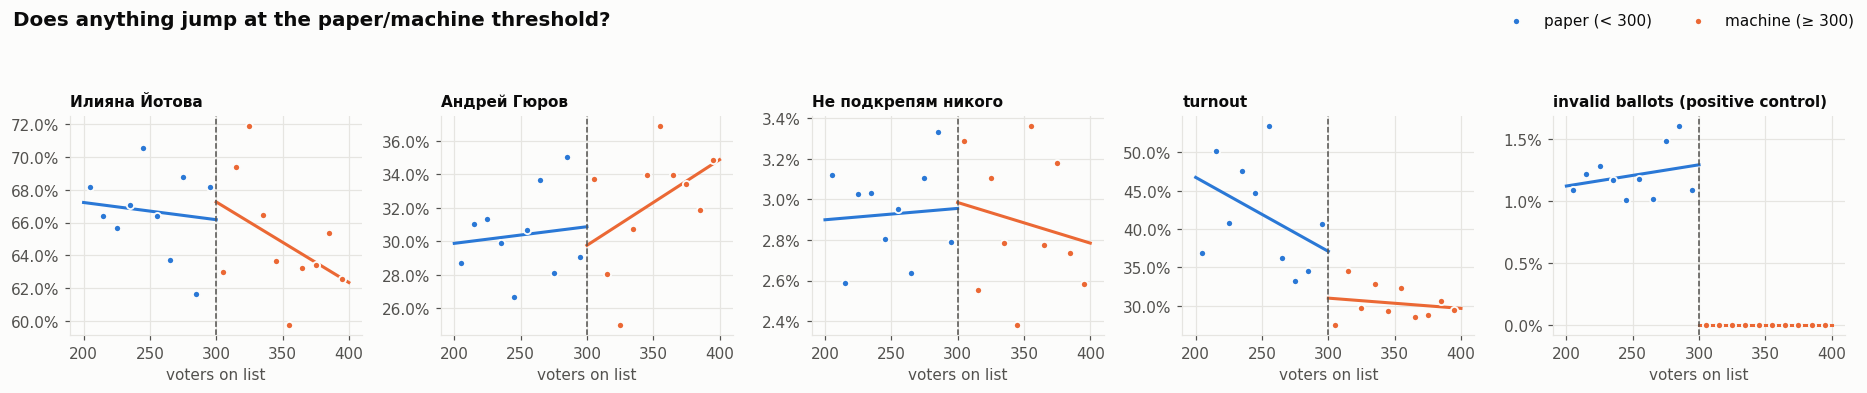

In [6]:
fig, axes = plt.subplots(1, len(rd_outcomes), figsize=(3.4 * len(rd_outcomes), 3.6))
BW = 100
s = dom[(dom["voters_list"] >= 300 - BW) & (dom["voters_list"] < 300 + BW)].copy()
s["bin"] = (s["voters_list"] // 10) * 10 + 5
for ax, (name, col) in zip(axes, rd_outcomes.items()):
    g = s.groupby("bin").apply(lambda t: np.average(t[col], weights=t["valid"]), include_groups=False)
    side = g.index >= 300
    ax.scatter(g.index[~side], g[~side], s=22, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="paper (< 300)")
    ax.scatter(g.index[side], g[side], s=22, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="machine (≥ 300)")
    for left, colr in [(True, BLUE), (False, ORANGE)]:
        t = s[(s["voters_list"] < 300) if left else (s["voters_list"] >= 300)]
        k = np.polyfit(t["voters_list"], t[col], 1, w=np.sqrt(t["valid"]))
        xx = np.array([200, 300]) if left else np.array([300, 400])
        ax.plot(xx, np.polyval(k, xx), color=colr, lw=2)
    ax.axvline(300, color=INK2, lw=1, ls="--")
    ax.set_title(name, fontsize=10); ax.set_xlabel("voters on list")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2)
suptitle(fig, "Does anything jump at the paper/machine threshold?")
fig.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

### Robustness: the turnout gap
The main table shows turnout ~6 pts *lower* on the machine side (municipality FE, ±100 voters); in round 1 there was no gap.
Higher turnout in paper stations could in principle mean stuffing, so we stress-test it:
* **Voter-list errors break the design.** A station whose committee wrote a too-small voter list (section 3 of the turnout notebook)
  *reports* fewer than 300 voters although it has machines, and shows ~100% turnout. Such stations land on the wrong side of the
  threshold. We drop stations with turnout ≥ 95%.
* **Bandwidth:** the answer shouldn't depend much on how wide a window around 300 we use.
* **Change between rounds:** if paper stations were stuffed in the runoff, the *increase* in turnout from round 1 would jump at 300.

In [7]:
r1m = load_sections(ROUND1)
dom["turnout r1"] = (r1m["voted_signatures"] / (r1m["voters_list"] + r1m["voters_added"])).reindex(dom.index)
dom["turnout change"] = dom["turnout"] - dom["turnout r1"]
no_err = dom[dom["turnout"] < 0.95]
rows = {}
for label, data, col in [("all stations", dom, "turnout"), ("excluding turnout ≥ 95%", no_err, "turnout"),
                         ("turnout change r1→r2, excl. ≥ 95%", no_err.dropna(subset=["turnout change"]), "turnout change")]:
    for bw in [50, 75, 100, 150]:
        b, se, n = rd_estimate(data, col, bw, fe=True)
        rows.setdefault(label, {})[f"±{bw}"] = f"{b*100:+.1f} ± {1.96*se*100:.1f}"
print("Turnout jump at 300 voters (machine − paper), pts, municipality FE, ± 95% CI")
print(f"stations reporting < 300 voters but having machines: {((dom['voters_list'] < 300) & ~dom['paper']).sum()}, "
      f"of which with turnout ≥ 95%: {((dom['voters_list'] < 300) & ~dom['paper'] & (dom['turnout'] >= 0.95)).sum()}")
pd.DataFrame(rows).T

Turnout jump at 300 voters (machine − paper), pts, municipality FE, ± 95% CI
stations reporting < 300 voters but having machines: 93, of which with turnout ≥ 95%: 72


,±50,±75,±100,±150
all stations,+0.3 ± 8.0,-3.8 ± 7.7,-6.6 ± 5.7,-6.0 ± 5.2
excluding turnout ≥ 95%,-0.4 ± 3.3,-1.4 ± 2.6,-3.0 ± 2.3,-4.0 ± 1.9
"turnout change r1→r2, excl. ≥ 95%",+4.3 ± 5.5,+2.1 ± 3.8,+0.2 ± 2.8,+0.7 ± 2.1


**Reading it:** the right-most panel is the **positive control**. Machines cannot produce invalid ballots, so the invalid share
*must* drop at 300, and the method detects that drop clearly. For the candidates the gaps are small and **inside the noise**:
Йотова +1.4 ± 2.9, Гюров −1.7 ± 2.7 pts (municipality FE, ±100 voters).

**The turnout gap is not robust.** 93 machine stations *report* fewer than 300 voters, 72 of them with ≥ 95% turnout, i.e. the
voter-list errors. Once those are dropped the gap shrinks to between −0.4 and −4 pts depending on the window, and the **change in
turnout since round 1 shows no jump at all** (+0.2 ± 2.8 at ±100). Paper stations were not stuffed in the runoff. The raw gap mostly
comes from voter-list errors putting machine stations on the wrong side of the line, plus ordinary small-village vs. town differences.

## 2. Invalid ballots (paper stations only)
Declaring valid ballots invalid during the count is a classic way to take votes from a rival. Two checks:
1. **Outliers:** stations with far more invalid ballots than the rest of their municipality. We use a **beta-binomial** model
   because invalid rates vary more between stations than pure chance would predict; a plain binomial test would flag far too many.
   Multiple testing is controlled with Benjamini–Hochberg (q < 0.01).
2. **Who loses when invalid ballots are high?** Within the same municipality, regress each candidate's share on the station's invalid rate.

In [8]:
P = dom[dom["paper"] & dom["form"].isin([24, 28])].copy()        # pure paper protocols
P["box"] = P["valid"] + P["invalid"]
P["invalid rate"] = P["invalid"] / P["box"]
nat_rate = P["invalid"].sum() / P["box"].sum()
P["municipality rate"] = loo_rate(P["invalid"], P["box"], P["municipality"], nat_rate)
P["q"], rho_inv = betabinom_outliers(P["invalid"], P["box"], P["municipality rate"].clip(lower=0.003))
P["flag_invalid"] = P["q"] < 0.01
print(f"paper stations: {len(P):,};  invalid ballots: {P['invalid'].sum():,} ({nat_rate:.2%});  "
      f"stations with zero invalid: {(P['invalid'] == 0).mean():.0%}")
print(f"over-dispersion ρ = {rho_inv:.3f};  flagged stations (q < 0.01): {P['flag_invalid'].sum()}")

paper stations: 2,468;  invalid ballots: 1,753 (1.44%);  stations with zero invalid: 62%
over-dispersion ρ = 0.017;  flagged stations (q < 0.01): 1


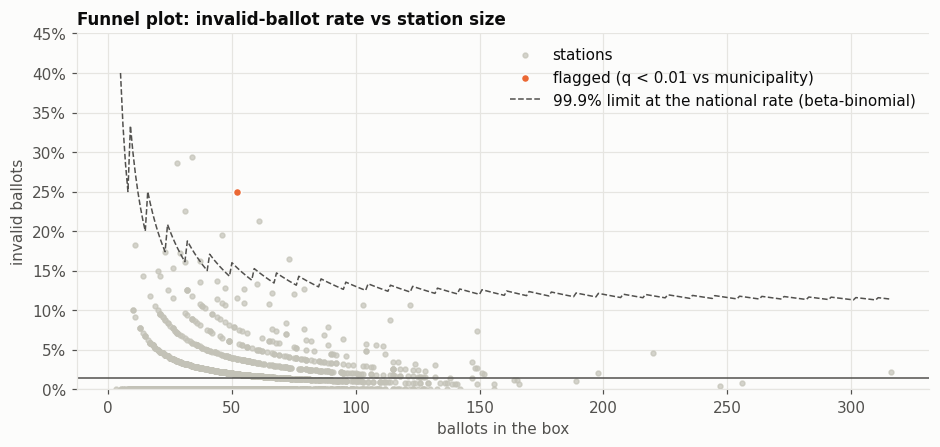

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ok = ~P["flag_invalid"]
ax.scatter(P.loc[ok, "box"], P.loc[ok, "invalid rate"], s=10, color=MUTED, alpha=0.7, label="stations", zorder=2)
ax.scatter(P.loc[~ok, "box"], P.loc[~ok, "invalid rate"], s=30, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=3,
           label="flagged (q < 0.01 vs municipality)")
nn = np.arange(5, P["box"].max() + 1)
a, b = nat_rate * (1 - rho_inv) / rho_inv, (1 - nat_rate) * (1 - rho_inv) / rho_inv
ax.plot(nn, stats.betabinom.ppf(0.999, nn, a, b) / nn, color=INK2, lw=1, ls="--", label="99.9% limit at the national rate (beta-binomial)")
ax.axhline(nat_rate, color=INK2, lw=1)
ax.set_xlabel("ballots in the box"); ax.set_ylabel("invalid ballots"); ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.45); ax.legend(loc="upper right")
ax.set_title("Funnel plot: invalid-ballot rate vs station size")
plt.show()

**Why so few (or no) flags?** Invalid-ballot rates vary much more between committees than chance alone allows (ρ above; more than half
of paper stations report zero invalid ballots, while others report 10–15%). That spread most likely reflects how strictly each
committee judges a doubtful ballot. Once this committee-to-committee variation is taken into account, no individual station stands out.
A plain binomial test would have flagged dozens of stations, but only because it ignores that spread.

In [10]:
P["top candidate"] = P[[f"share|{c}" for c in cand_cols]].idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
P.loc[P["flag_invalid"], ["place", "address", "box", "invalid", "invalid rate", "municipality rate", "top candidate", "q"]] \
    .sort_values("q").style.format({"invalid rate": "{:.1%}", "municipality rate": "{:.1%}", "q": "{:.1e}"})

,place,address,box,invalid,invalid rate,municipality rate,top candidate,q
section,,,,,,,,
131900095,гр.Пазарджик,"Дом за стари хора Гаврил Кръстевич гр. Пазарджик, ул. ‘‘Болнична № 22",52,13,25.0%,0.7%,Илияна Йотова,7.7e-03


In [11]:
rows = {}
for c in OUTCOMES:
    X = demean(P[["invalid rate"]], P["municipality"], P["box"])
    y = demean(P[f"share|{c}"], P["municipality"], P["box"])[:, 0]
    b, se = wls_cluster(y, X, P["box"], P["municipality"])
    rows[short(c)] = {"slope": b[0], "95% CI": f"{b[0] - 1.96*se[0]:+.2f} … {b[0] + 1.96*se[0]:+.2f}",
                      "share change if invalid rate +5 pts": b[0] * 0.05}
inv_slopes = pd.DataFrame(rows).T
inv_slopes.style.format({"slope": "{:+.2f}", "share change if invalid rate +5 pts": "{:+.1%}"})

,slope,95% CI,share change if invalid rate +5 pts
Илияна Йотова,-0.23,-0.46 … -0.01,-1.2%
Андрей Гюров,+0.14,-0.10 … +0.38,+0.7%
Не подкрепям никого,+0.09,+0.02 … +0.16,+0.5%


**How to read the slopes.** If invalid ballots were a random slice of all ballots, every slope would be ~0. If they were taken
entirely from candidate X, X's slope would be close to −(1 − X's share): about −0.4 for Йотова and −0.6 for Гюров.

A negative slope for a candidate whose voters are younger or more educated can also be innocent. Older, less experienced voters
spoil more ballots and vote differently, even within one municipality. The RDD in section 1 helps: if paper counts were
systematically hurting a candidate, that candidate would gain at the switch to machines, and no such jump appears.

**Scale check:** see the count of invalid ballots printed above. Even if every one had been stolen from one candidate, it is tiny
compared with the 343,601-vote margin.

## 3. Voters added on election day (“под чертата”)
Voters not on the printed list can be added on the day (e.g. voting at a temporary address). Adding fictitious voters is a known
channel for fraud. Two checks:

**(a) How do added voters vote?** Each station's result mixes regular voters and added voters. Regressing a candidate's share on
the station's fraction of added voters (comparing stations in the same municipality) estimates **the share among added voters**.

**Watch out for a trap:** the added fraction (added ÷ voted) is mechanically larger where turnout is low. Any candidate who is strong in
low-turnout stations will therefore *look* popular among added voters. So we show the estimate **with and without controlling for
turnout**.

In [12]:
A = dom[(dom["registered"] >= 100) & (dom["voters_added"] / dom["registered"] <= 0.5)].copy()
A["added fraction"] = A["voters_added"] / A["voted"].clip(lower=1)
A = A[A["added fraction"] <= 1]
turnout_deciles = pd.get_dummies(pd.qcut(A["turnout"], 10), drop_first=True).astype(float)

def added_voter_share(data, cand, group, control_turnout):
    Xraw = data[["added fraction"]]
    if control_turnout:
        Xraw = pd.concat([Xraw, turnout_deciles.loc[data.index]], axis=1)
    keep = (data.groupby(group)["added fraction"].transform("size") >= 2).to_numpy()
    X = demean(Xraw, data[group], data["valid"])[keep]
    y = demean(data[f"share|{cand}"], data[group], data["valid"])[keep, 0]
    b, se = wls_cluster(y, X, data["valid"][keep], data[group][keep])
    base = data[cand].sum() / data["valid"].sum()
    return base, base + b[0], 1.96 * se[0]

specs = {"naive (same municipality)": ("municipality", False),
         "+ control for turnout": ("municipality", True),
         "+ turnout, same building": ("address", True)}
est = {}
for c in OUTCOMES:
    for name, (g, ctl) in specs.items():
        base, val, ci = added_voter_share(A, c, g, ctl)
        est[(short(c), name)] = (base, val, ci)
tab = pd.DataFrame({k: {"regular voters (overall)": v[0], "added voters (est.)": v[1], "± 95% CI": v[2]} for k, v in est.items()}).T
print(f"{len(A):,} stations, {A['voters_added'].sum():,} added voters ({A['voters_added'].sum() / A['voted'].sum():.1%} of all who voted)")
tab.style.format("{:.1%}")

10,653 stations, 68,444 added voters (3.9% of all who voted)


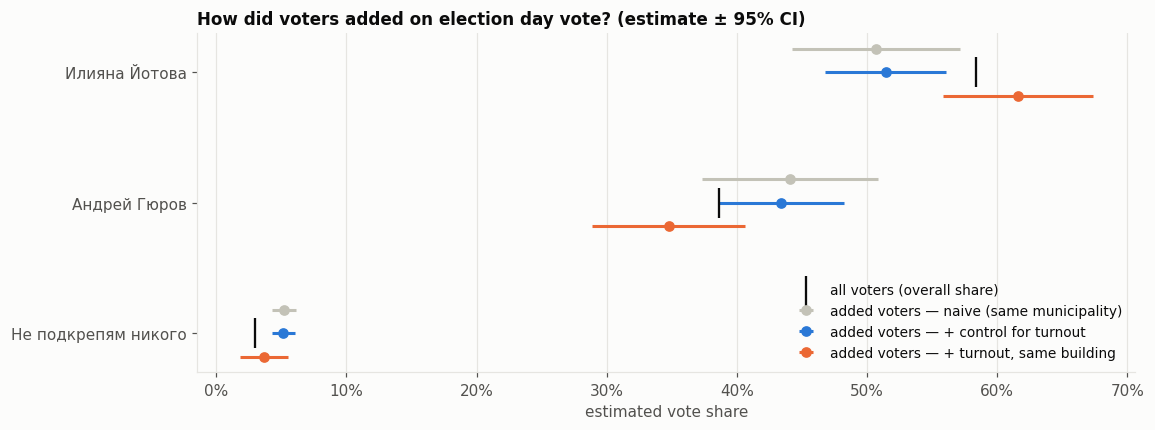

In [13]:
fig, ax = plt.subplots(figsize=(11, 4))
cands = [short(c) for c in OUTCOMES]
y0 = np.arange(len(cands))
offsets = {"naive (same municipality)": -0.18, "+ control for turnout": 0.0, "+ turnout, same building": 0.18}
colors = {"naive (same municipality)": MUTED, "+ control for turnout": BLUE, "+ turnout, same building": ORANGE}
for name, off in offsets.items():
    vals = [est[(c, name)] for c in cands]
    ax.errorbar([v[1] for v in vals], y0 + off, xerr=[v[2] for v in vals], fmt="o", ms=6, color=colors[name],
                ecolor=colors[name], elinewidth=2, capsize=0, label=f"added voters — {name}")
ax.scatter([est[(c, 'naive (same municipality)')][0] for c in cands], y0, marker="|", s=400, color=INK, zorder=4, label="all voters (overall share)")
ax.set_yticks(y0, cands); ax.invert_yaxis(); ax.xaxis.set_major_formatter(pct); ax.grid(axis="y", visible=False)
ax.set_xlabel("estimated vote share"); ax.legend(loc="lower right", fontsize=9)
ax.set_title("How did voters added on election day vote? (estimate ± 95% CI)")
plt.show()

**(b) Stations with unusually many added voters** relative to the rest of their municipality (added ÷ registered, beta-binomial,
q < 0.01). Hospitals and prisons were already excluded, but some flagged stations will have innocent reasons: student dorms, resorts,
workplaces.

In [14]:
A["added rate"] = A["voters_added"] / A["registered"]
nat_added = A["voters_added"].sum() / A["registered"].sum()
A["municipality added rate"] = loo_rate(A["voters_added"], A["registered"], A["municipality"], nat_added)
A["q_added"], rho_add = betabinom_outliers(A["voters_added"], A["registered"], A["municipality added rate"].clip(lower=0.002))
A["flag_added"] = A["q_added"] < 0.01
A["top candidate"] = A[[f"share|{c}" for c in cand_cols]].idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
A["top share"] = A[[f"share|{c}" for c in cand_cols]].max(axis=1)
print(f"over-dispersion ρ = {rho_add:.3f};  flagged stations: {A['flag_added'].sum()}")
A.loc[A["flag_added"], ["place", "address", "registered", "voters_added", "voted", "added rate", "municipality added rate",
                         "top candidate", "top share", "q_added"]].sort_values("q_added").head(40).style.format(
    {"added rate": "{:.1%}", "municipality added rate": "{:.1%}", "top share": "{:.0%}", "q_added": "{:.1e}"})

over-dispersion ρ = 0.005;  flagged stations: 66


,place,address,registered,voters_added,voted,added rate,municipality added rate,top candidate,top share,q_added
section,,,,,,,,,,
234610115,гр.София,"ВОЕННОМЕДИЦИНСКА АКАДЕМИЯ, бул. „Св. Георги Софийски” № 3, учебна зала № 2, първи етаж /ет. I/ в основната сграда на ВМА",890,197,247,22.1%,2.1%,Илияна Йотова,51%,0.0e+00
234609083,гр.София,бул. „Никола Вапцаров“ № 51-Б,695,230,256,33.1%,2.1%,Андрей Гюров,60%,0.0e+00
234610111,гр.София,"СБАЛАГ „МАЙЧИН Дом” ЕАД, ул. „Здраве” № 2, кабинет 121, първи етаж /ет. I/- основна сграда",207,77,95,37.2%,2.2%,Андрей Гюров,46%,0.0e+00
234610114,гр.София,"УМБАЛ „СВ. ИВАН РИЛСКИ“ ЕАД, бул. Акад. Иван Гешов 15, главно фоайе на УМБАЛ „СВ. ИВАН РИЛСКИ“ ЕАД",225,105,120,46.7%,2.2%,Илияна Йотова,57%,0.0e+00
273100063,гр.Стара Загора,"ГР.СТАРА ЗАГОРА, Дом на инвалида - кинозала, ул. Хан Аспарух №47",158,37,89,23.4%,1.1%,Илияна Йотова,62%,0.0e+00
234616002,гр.София,"ГР.СОФИЯ, ж.к. Студентски град ,бл.26,ет.ІІ",845,355,580,42.0%,2.1%,Андрей Гюров,71%,0.0e+00
234616003,гр.София,"ГР.СОФИЯ, ж.к. Студентски град ,бл.38,ет.ІІ",805,216,536,26.8%,2.1%,Андрей Гюров,76%,0.0e+00
234616005,гр.София,"ГР.СОФИЯ, ж.к. Студентски град ,бл.13,ет.ІІ",996,369,660,37.0%,2.1%,Андрей Гюров,72%,0.0e+00
220900024,гр.Девин,"СБР „ОРФЕЙ“ ЕООД, ул. „Цветан Зангов“ 14, Конферентна зала България",110,37,80,33.6%,0.7%,Илияна Йотова,61%,0.0e+00


In [15]:
flagged = A[A["flag_added"]]
comp = pd.DataFrame({
    "flagged stations": flagged[OUTCOMES].sum() / flagged["valid"].sum(),
    "all stations": A[OUTCOMES].sum() / A["valid"].sum(),
})
comp.index = [short(c) for c in comp.index]
print(f"Vote shares in the {len(flagged)} stations with unusually many added voters vs everywhere:")
comp.style.format("{:.1%}")

Vote shares in the 66 stations with unusually many added voters vs everywhere:


,flagged stations,all stations
Илияна Йотова,39.8%,58.4%
Андрей Гюров,56.7%,38.7%
Не подкрепям никого,3.5%,3.0%


## 4. Do the protocols add up?
The CIK data-entry software rejects many inconsistent protocols, so most identities hold by construction. What slips through is
still informative:

In [16]:
pp = main.reindex(dom.index)
f = dom["form"]
paper_f, mach_f = f.isin([24, 28]), f.isin([25, 29])
sig, box, inv_, valid7, cand71, none72 = (num(pp[i]) for i in (11, 12, 13, 15, 16, 17))
received, destroyed, unused = num(pp[6]), num(pp[7]), num(pp[8])
mach_votes = num(pp[14])
cand_sum = dom[cand_cols].sum(axis=1)

checks = {
    "paper: signatures ≠ ballots in the box": paper_f & (sig != box),
    "paper: ballots in box ≠ invalid + valid": paper_f & (box != inv_ + valid7),
    "paper: valid ≠ candidates + 'none'": paper_f & (valid7 != cand71 + none72),
    "paper: received ≠ destroyed + unused + in box": paper_f & (received != destroyed + unused + box),
    "machine: signatures ≠ machine votes": mach_f & (sig != mach_votes),
    "votes per candidate ≠ protocol item 7.1": paper_f & (cand_sum != cand71),
    "more voters than registered": dom["voted"] > dom["registered"],
}
check_df = pd.DataFrame(checks)
dom["arith_issues"] = check_df.apply(lambda r: "; ".join(k for k, v in r.items() if v), axis=1)
dom["flag_arith"] = check_df.any(axis=1)
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="stations").to_frame()

,stations
paper: signatures ≠ ballots in the box,0
paper: ballots in box ≠ invalid + valid,0
paper: valid ≠ candidates + 'none',0
paper: received ≠ destroyed + unused + in box,0
machine: signatures ≠ machine votes,21
votes per candidate ≠ protocol item 7.1,0
more voters than registered,1


In [17]:
detail = dom.loc[dom["flag_arith"], ["place", "form", "registered", "voted"]].copy()
detail["signatures"] = sig[dom["flag_arith"]]
detail["ballots in box / machine votes"] = np.where(paper_f[dom["flag_arith"]], box[dom["flag_arith"]], mach_votes[dom["flag_arith"]])
detail["difference"] = detail["signatures"] - detail["ballots in box / machine votes"]
detail["issues"] = dom.loc[dom["flag_arith"], "arith_issues"]
detail.sort_values("difference", key=abs, ascending=False)

,place,form,registered,voted,signatures,ballots in box / machine votes,difference,issues
section,,,,,,,,
013300034,гр.Петрич,25,877,221,221,0.0,221.0,machine: signatures ≠ machine votes
264300023,с.Церово,25,607,162,162,157.0,5.0,machine: signatures ≠ machine votes
011100040,с.Лъжница,25,796,111,111,115.0,-4.0,machine: signatures ≠ machine votes
012800003,гр.Кресна,25,247,250,250,247.0,3.0,machine: signatures ≠ machine votes; more vote...
050900046,гр.Видин,25,486,162,162,159.0,3.0,machine: signatures ≠ machine votes
303000123,с.Царев брод,25,574,106,106,104.0,2.0,machine: signatures ≠ machine votes
301000018,с.Тушовица,25,829,205,205,203.0,2.0,machine: signatures ≠ machine votes
283500086,с.Острец,25,379,39,39,37.0,2.0,machine: signatures ≠ machine votes
283500017,гр.Търговище,25,799,231,231,229.0,2.0,machine: signatures ≠ machine votes


**Reading it:** a difference of 1–2 between signatures and ballots happens honestly (a voter signs and leaves, or forgets to sign).
Large gaps (dozens of ballots) mean either a serious recording error or ballots that can't be accounted for. They are the first
protocols to look up.

## 5. Combined watch-list
One flag alone is usually innocent. **Several independent flags in the same station** are much more interesting. We combine the
flags from this notebook with those from the turnout notebook:

| flag | meaning |
|---|---|
| `invalid` | far more invalid ballots than the municipality (q < 0.01) |
| `added` | far more voters added on the day than the municipality (q < 0.01) |
| `arith` | protocol doesn't add up |
| `list_error` | ~100% turnout with a voter list much smaller than the same-building neighbours |
| `extreme` | turnout > 70% and one candidate > 85% (runoff threshold; 70% shares are ordinary in a two-way race) |
| `low_t_bloc` | turnout < 40% of the municipality median and one candidate > 85% |
| `surge` | turnout rose > 15 pts more than in the rest of the municipality since round 1, with a stable voter list |
| `r1_watchlist` | the station was already on the round-1 watch-list (`watchlist.csv`) |

In [18]:
w = dom.copy()
w["flag_invalid"] = P["flag_invalid"].reindex(w.index, fill_value=False)
w["flag_added"] = A["flag_added"].reindex(w.index, fill_value=False)

bld_list = w.groupby("address")["voters_list"].transform(lambda s: s.sum() - s) / (w.groupby("address")["voters_list"].transform("size") - 1)
w["flag_list_error"] = (w["turnout"] >= 0.95) & (w["voters_list"] < 0.6 * bld_list)

shares = w[[f"share|{c}" for c in cand_cols]]
w["top candidate"] = shares.idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
w["top share"] = shares.max(axis=1)
regular = (w["registered"] >= 100) & (w["voters_added"] / w["registered"] <= 0.5)
w["flag_extreme"] = regular & (w["turnout"] > 0.7) & (w["top share"] > 0.85)
muni_t = w[regular].groupby("municipality")["turnout"].median()
w["flag_low_t_bloc"] = regular & (w["turnout"] < 0.4 * w["municipality"].map(muni_t)) & (w["top share"] > 0.85)

# cross-round flags
r1m = load_sections(ROUND1)
r1_t = r1m["voted_signatures"] / (r1m["voters_list"] + r1m["voters_added"])
r1_reg = (r1m["voters_list"] + r1m["voters_added"]).reindex(w.index)
w["dt"] = w["turnout"] - r1_t.reindex(w.index)
w["dt_rel"] = w["dt"] - w.groupby("municipality")["dt"].transform("median")
w["flag_surge"] = regular & (r1_reg >= 100) & ((w["registered"] / r1_reg - 1).abs() < 0.3) & (w["dt_rel"] > 0.15)
try:
    r1_watch = pd.read_csv("watchlist.csv", dtype={"section": str}).set_index("section")
    w["flag_r1_watchlist"] = w.index.isin(r1_watch.index)
    w["round-1 flags"] = r1_watch["flags"].reindex(w.index).fillna("")
except FileNotFoundError:
    w["flag_r1_watchlist"] = False
    w["round-1 flags"] = ""

FLAGS = ["flag_invalid", "flag_added", "flag_arith", "flag_list_error", "flag_extreme", "flag_low_t_bloc", "flag_surge", "flag_r1_watchlist"]
w["n_flags"] = w[FLAGS].sum(axis=1)
w["flags"] = w[FLAGS].apply(lambda r: ", ".join(k.replace("flag_", "") for k, v in r.items() if v), axis=1)

NEW_FLAGS = [f for f in FLAGS if f != "flag_r1_watchlist"]
w["n_new_flags"] = w[NEW_FLAGS].sum(axis=1)
summary = pd.Series({k.replace("flag_", ""): int(w[k].sum()) for k in FLAGS} |
                    {"≥ 2 round-2 flags": int((w["n_new_flags"] >= 2).sum()), "≥ 2 flags incl. round 1": int((w["n_flags"] >= 2).sum())}, name="stations")
summary.to_frame()

,stations
invalid,1
added,66
arith,21
list_error,45
extreme,3
low_t_bloc,41
surge,38
r1_watchlist,240
≥ 2 round-2 flags,6
≥ 2 flags incl. round 1,79


In [19]:
watch = w[w["n_new_flags"] >= 1].sort_values(["n_flags", "top share"], ascending=False)
cols = ["n_flags", "flags", "round-1 flags", "place", "address", "registered", "voters_added", "voted", "turnout", "dt", "invalid", "top candidate", "top share"]
watch[cols].to_csv("watchlist_round2.csv")
print(f"{len(watch)} stations with at least one round-2 flag saved to watchlist_round2.csv")
watch.loc[watch["n_flags"] >= 2, cols].style.format({"turnout": "{:.0%}", "dt": "{:+.0%}", "top share": "{:.0%}"})

209 stations with at least one round-2 flag saved to watchlist_round2.csv


,n_flags,flags,round-1 flags,place,address,registered,voters_added,voted,turnout,dt,invalid,top candidate,top share
section,,,,,,,,,,,,,
171300078,3,"added, surge, r1_watchlist",added,гр.Баня,"Специализирана болница за рехабилитация НК – филиал гр. Баня, ул. “Липите“ № 1",116,38,104,90%,+22%,0,Илияна Йотова,63%
220900024,3,"added, surge, r1_watchlist",added,гр.Девин,"СБР „ОРФЕЙ“ ЕООД, ул. „Цветан Зангов“ 14, Конферентна зала България",110,37,80,73%,+24%,1,Илияна Йотова,61%
021700049,3,"added, surge, r1_watchlist",added,гр.Поморие,"ГР.ПОМОРИЕ, СБР-НК ЕАД Филиал Поморие /спец.болница за рехабилитация/",157,34,122,78%,+21%,0,Илияна Йотова,61%
254624015,3,"added, surge, r1_watchlist",added,гр.Банкя,"СБР „Здраве“ ЕАД, ул. „Г. С. Раковски“ № 15",302,71,149,49%,+22%,11,Илияна Йотова,59%
291700010,2,"low_t_bloc, r1_watchlist",low_t_bloc,гр.Любимец,"ГР.ЛЮБИМЕЦ, бул. Одрин №81 Спортна зала Граничар",633,6,55,9%,+7%,0,Илияна Йотова,98%
010200011,2,"surge, r1_watchlist",low_t_bloc,с.Бабяк,"С.БАБЯК, УЧИЛИЩЕ",594,6,348,59%,+57%,0,Андрей Гюров,97%
291700011,2,"low_t_bloc, r1_watchlist",low_t_bloc,гр.Любимец,"ГР.ЛЮБИМЕЦ, бул. Одрин №81 Спортна зала Граничар",474,1,36,8%,+4%,0,Илияна Йотова,94%
173900004,2,"low_t_bloc, r1_watchlist",low_t_bloc,гр.Кричим,"ГР.КРИЧИМ, Дневен център за стари хора, бул.Ал.Стамболийски №27А",1006,2,49,5%,+4%,0,Илияна Йотова,92%
015300012,2,"surge, r1_watchlist",low_t_bloc,с.Бунцево,"С.БУНЦЕВО, КМЕТСТВО",371,4,212,57%,+55%,0,Андрей Гюров,92%


In [20]:
# Which candidate leads in flagged stations, compared with how often each candidate leads overall?
lead_all = w.loc[regular, "top candidate"].value_counts(normalize=True)
lead_flag = pd.DataFrame({k.replace("flag_", ""): w.loc[w[k], "top candidate"].value_counts() for k in FLAGS}).fillna(0).astype(int)
lead_flag["share of all stations they lead"] = lead_all.reindex(lead_flag.index)
lead_flag.sort_values("share of all stations they lead", ascending=False).head(8).style.format({"share of all stations they lead": "{:.0%}"})

,invalid,added,arith,list_error,extreme,low_t_bloc,surge,r1_watchlist,share of all stations they lead
top candidate,,,,,,,,,
Илияна Йотова,1,36,18,38,2,40,16,172,80%
Андрей Гюров,0,30,3,7,1,1,22,68,20%


## 6. Conclusions

| Check | Finding | Fraud signal? |
|---|---|---|
| **Paper vs machine (RDD at 300)** | No jump for either candidate: Йотова +1.4 ± 2.9, Гюров −1.7 ± 2.7 pts. The positive control (invalid ballots) is detected clearly. | **No** systematic paper-count manipulation |
| **Turnout at the threshold** | A raw −6.6 pt gap that collapses once voter-list errors are removed; no jump in the turnout *change* from round 1 | **No** |
| **Bunching at 300** | Again *fewer* stations just below 300 (101 vs 133), as in round 1 | **No** |
| **Invalid ballots** | 1.4% of paper ballots (1,753); 1 outlier, a care home in Пазарджик (13 of 52 invalid, elderly voters). Invalid rate vs. share: Йотова −1.2 pts per +5 pts of invalid ballots, the opposite direction to round 1 and tiny. | **No** |
| **Added voters** | 68,444 added (3.9%). Their estimated vote split isn't robust (it flips between specifications); they choose “none” somewhat more often. The 66 outlier stations are student dorms, hospitals, sanatoria, prisons and the Military Medical Academy. | **No** |
| **Protocol arithmetic** | 21 machine stations off by 1–5. One big gap: Петрич 013300034 (221 signatures, “0” machine votes), where the committee entered the reading of an unused second machine. The machine data show 221 votes, matching the count. | **No.** Recording slips |
| **Combined watch-list** | 209 stations with a round-2 flag; **only 6 with two round-2 flags**: 4 rehabilitation hospitals (added voters + turnout swing, where patients change weekly) and 2 small stations. | **No multi-flag hotspots** |
| **Repeat offenders** (flagged in both rounds) | **9 stations are low-turnout blocs in both rounds**: Любимец ×2, Пещера and Вършец went from Василев (r1) to Йотова (r2) at 88–98%; Кричим, Перущица, Сливо поле, Майско and Крушаре were Йотова blocs both times (86–92% in r2). Бабяк and Бунцево (Белица): near-zero turnout in r1, then 57–59% turnout at 92–97% Гюров. | **The most specific leads in the whole analysis.** Small (≈ 600 votes in the 9 bloc stations), but consistent across two elections |

### Bottom line
**The runoff's counting stage looks as clean as round 1's.** Paper and machine stations agree; invalid ballots and added voters behave
normally; protocols add up apart from recording slips.

What survives two rounds of testing is a **short list of stations with organised-looking voting**: neighbourhoods that barely vote
except for a compact bloc for one candidate, and a few villages that jumped from abstention to near-unanimous turnout for one
candidate. These favour **both** runoff candidates in different places and are worth checking against observer reports. They involve
hundreds to a few thousand votes against a **343,601-vote margin**.

### Across all six notebooks
| | Round 1 | Round 2 (runoff) |
|---|---|---|
| Invented numbers (Benford, digits) | none | none |
| Ballot stuffing (turnout fingerprint) | none | none; runoff turnout rose evenly (+5 pts) and new voters split like the rest |
| Counting-stage manipulation | none | none |
| Data-quality issues | 39 voter-list errors, 2 small arithmetic mismatches | 42 voter-list errors (only 12 repeat), 21 machine recording slips |
| Organised-voting patterns | ~56 low-turnout blocs, mostly Василев | mobilisation of round-1 abstainers for Гюров (Кърджали, Белица, Якоруда, Шумен, Хасково; net ≈ +4,900); 9 repeat bloc stations, mostly Йотова |

`watchlist_round2.csv` lists every flagged station with its round-2 and round-1 flags.